# Load data

In [ ]:
import rpy2.robjects as robjects
from rpy2.robjects import numpy2ri
import numpy as np
import pickle

# --- Setup rpy2 ---
# This line is crucial to allow conversion between R and NumPy objects
numpy2ri.activate()

# Define file paths
rdata_path = 'FRED-MD data/fredmd_data.RData'
output_path = 'FRED-MD data/fredmd_data.pkl'

print(f"Attempting to load '{rdata_path}' using rpy2...")

try:
    # --- Use R to load the data, supplied from Cho ---
    # This command is sent to the R process to execute: load("fredmd_data.RData")
    robjects.r(f"load('{rdata_path}')")

    # --- Access the loaded R object ---
    # After loading, the 'fredmd_data' object exists in R's global environment.
    # We can access it by name.
    r_object = robjects.r['fredmd_data']

    print("Successfully accessed the 'fredmd_data' object from R.")

    # --- Convert the R object to a Python dictionary of NumPy arrays ---
    # We access each component of the R list using .rx2('component_name')
    # and convert it to a NumPy array.
    python_data = {
        'X': np.array(r_object.rx2('X')),
        'y': np.array(r_object.rx2('y')).flatten(), # .flatten() to ensure 1D
        'date': np.array(r_object.rx2('date')).flatten()
    }
    
    print("\nData converted to Python format successfully.")
    print("Shape of X:", python_data['X'].shape)
    print("Shape of y:", python_data['y'].shape)
    print("Number of dates:", len(python_data['date']))

    # --- Save to a Python-native format ---
    # This is highly recommended so you don't have to do this conversion again.
    with open(output_path, 'wb') as f:
        pickle.dump(python_data, f)
    

except Exception as e:
    print(f"\nAn error occurred: {e}")
    print("Please ensure that R is installed and that the rpy2 Python package is installed correctly.")

Attempting to load 'FRED-MD data/fredmd_data.RData' using rpy2...
Successfully accessed the 'fredmd_data' object from R.

Data converted to Python format successfully.
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773

Data has been saved to 'FRED-MD data/fredmd_data.pkl'. You can now load this file directly in future Python scripts.


In [ ]:
import pickle
import numpy as np

# Define the path to your .pkl file
pkl_path = '/scratch/ga442/Weighted-ERM/FRED-MD data/fredmd_data.pkl'

# Open the file in binary read mode ('rb')
with open(pkl_path, 'rb') as f:
    # Load the data from the file
    loaded_data = pickle.load(f)

# Assign the data to your variables
X = loaded_data['X']
y = loaded_data['y']
date = loaded_data['date']
X_ = X.copy()
y_ = y.copy()
date_ = date.copy()

# --- Verification (Optional but good practice) ---
print("Data loaded successfully!")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")
print(f"Number of dates: {len(date)}")
print(f"First 5 dates: {date[:5]}")# Load the python

Data loaded successfully!
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773
First 5 dates: ['1960-01' '1960-02' '1960-03' '1960-04' '1960-05']


# Linear Model with Huber Loss 

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.16832987154363713
        x: [-1.287e+00  5.522e-02 ... -8.183e-02 -2.693e-03]
      nit: 548
      jac: [-3.135e-06  5.303e-06 ... -1.669e-06 -1.791e-05]
     nfev: 575
     njev: 575
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


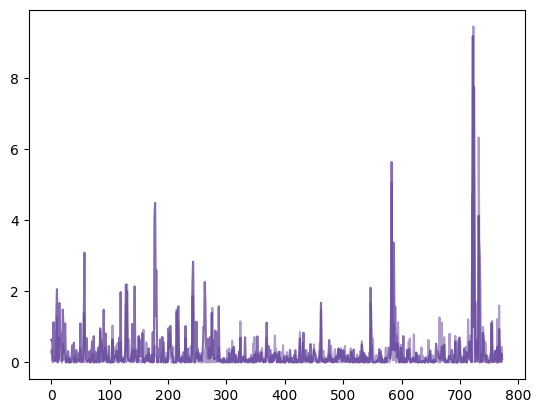

Regressing on signal  1
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.14670697544209377
        x: [-1.048e+00  1.551e-01 ... -2.985e-02 -1.879e-02]
      nit: 461
      jac: [ 1.868e-06 -9.054e-07 ...  3.017e-06 -8.995e-06]
     nfev: 478
     njev: 478
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


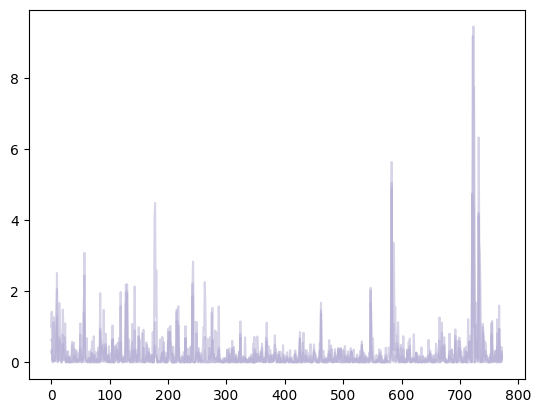

Regressing on signal  2
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.1422996998944905
        x: [-8.936e-01  3.396e-01 ...  3.081e-01  7.856e-02]
      nit: 1024
      jac: [ 7.257e-06  3.382e-06 ...  6.217e-06 -4.076e-06]
     nfev: 1068
     njev: 1068
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


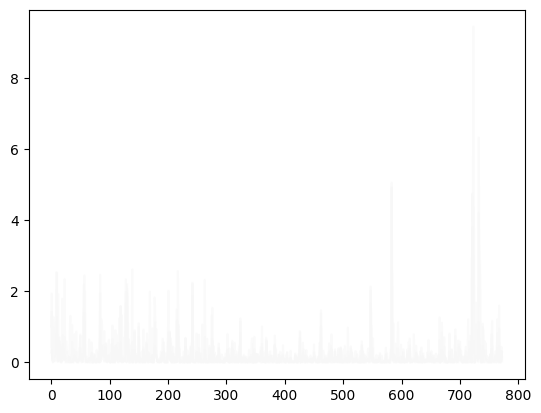

Optimizing gof erm...
WERM chpt estimate:  [264 611]
WERM gof:  105.1077259250802
Change point dates (ERM):  ['1982-01' '2010-12']
Done optimizing gof erm.


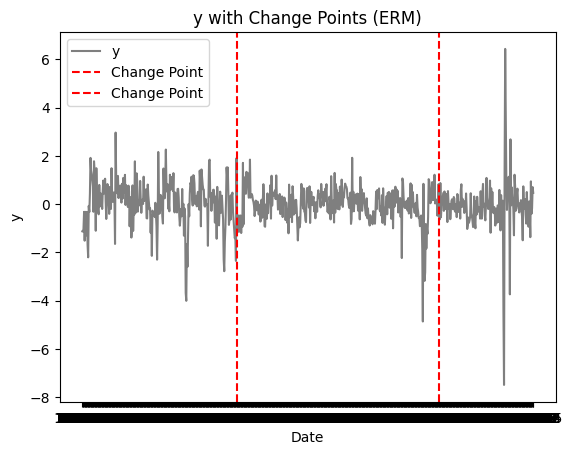

In [9]:
from WERM.config import unif_prior_to_η_ϕ
import WERM.gof
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import matplotlib.pyplot as plt
import scipy
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

start_idx = 0
X = X_[start_idx:, :]
y = y_[start_idx:]
date = date_[start_idx:]
# Downsample the data by 2
# downsample_factor = 1
# X = X_[::downsample_factor, :]
# y = y_[::downsample_factor]
# date = date_[::downsample_factor]

n, p = X.shape
L = 3 # num signals. L-1 changepoints

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
def M(u, v, epsilon=1.345):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# --- Preliminaries ---
# Set up the marginal prior
# Δ = lambda n: int(n/100)
Δ = lambda n: 1
# Lmin = L
# Lmax = L
# # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
# p_l = None
# num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
# assert η_arr.shape == (num_valid_configs, Lmax-1) and \
#     len(p_η_arr) == num_valid_configs
# assert ϕ.shape == (Lmax, n)

### --- Compute weights using analytical formula --- ###
# Weights computed according to {L-1 choose ℓ -1} * (i/n)^{ℓ-1} * (1 - i/n)^{L-ℓ}
# where ℓ is the number of signals, i is the index of the signal, and n is the total number of signals.
π = lambda ℓ, i, n: (scipy.special.comb(L-1, ℓ-1) * (i/n)**(ℓ-1) * (1 - i/n)**(L-ℓ))
ϕ = np.zeros((L, n)) # Lxn matrix
for ℓ in range(1, L+1):
    for i in range(1, n+1):
        ϕ[ℓ-1, i-1] = π(ℓ, i, n)
# Normalize ϕ so that it sums to 1 for each signal
ϕ = ϕ / np.sum(ϕ, axis=1, keepdims=True) # Lxn matrix

# --- Run Weighted ERM and compare with the fixed point equations --- #
B̂ = np.zeros((p, L))

# Time the execution of the ERM and save it
start_time_erm = time.time()
for ℓ_ in range(L): 

    # Compute the empirical risk minimization (ERM) solution and metrics
    print("Regressing on signal ", ℓ_)
    sample_weight = ϕ[ℓ_, :] / np.sum(ϕ[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

    # Compute weighted ERM estimator
    empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
    res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
    print("ERM opt result: ", res) 
    β̂ = res.x
    B̂[:, ℓ_] = β̂

    ### --- Compute Change point estimates --- ###

    ## Compute Chgpt estimate for ERM
    PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99'] * 4
    for ℓ in range(L):
        plt.plot(np.arange(n), M(X @ B̂[:, ℓ], y), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ)) 
    plt.show()

print("Optimizing gof erm...")
# η̂, gof_list = WERM.gof.chgpt_gof(M, X @ B̂, y, η_arr, p_η_arr, γ = 1, gof_list_output = True)
# η̂, gof_list = WERM.gof.chgpt_gof_binary_seg(M, X @ B̂, y, η_arr, p_η_arr, γ = 1.0, combinations = True, gof_list_output = False, min_window_size = 30)
η̂, opt_gof = WERM.gof.chgpt_gof_binary_seg_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=0.0, min_window_size=300, gof_opt_output=True)
# η̂ = WERM.gof.chgpt_gof_brute_force_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=1.0, batch_size=4096)
# # Scatter the gof list
# plt.scatter(np.arange(len(gof_list)), gof_list, c='blue', alpha=0.5)
# plt.title('Goodness of Fit for Change Point Estimates (ERM)')
# plt.xlabel('Change Point Estimate (η)')
# plt.ylabel('Goodness of Fit')
# plt.grid()
# plt.show()
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", η̂)
print("WERM gof: ", opt_gof)
# Print the dates associated with the change points
chgpt_dates_erm = date[η̂]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

WERM chpt estimate:  [155 334 654]
Change point dates (ERM):  ['1972-12' '1987-11' '2014-07']
Done optimizing gof erm.


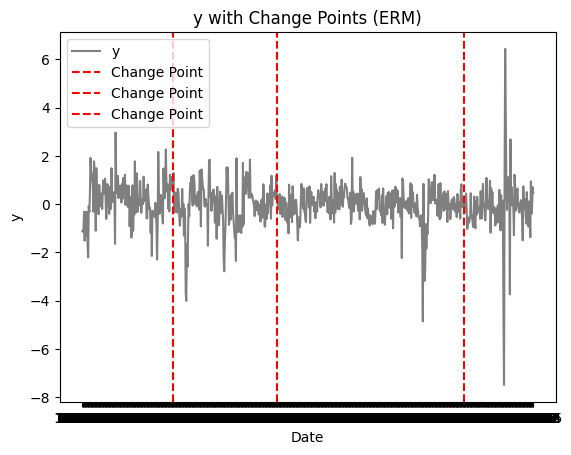

In [9]:
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", η̂)
# Print the dates associated with the change points
chgpt_dates_erm = date[η̂]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

In [11]:
# Save results to logs
results = {
    'B̂': B̂,
    'η̂': η̂,
    'chgpt_dates_erm': chgpt_dates_erm
}
# Save the results to a file
with open('WERM_results_bf.pkl', 'wb') as f:
    pickle.dump(results, f)
# Print the results
print("Results saved to 'WERM_results.pkl'.")
# Load the results from the file

Results saved to 'WERM_results.pkl'.


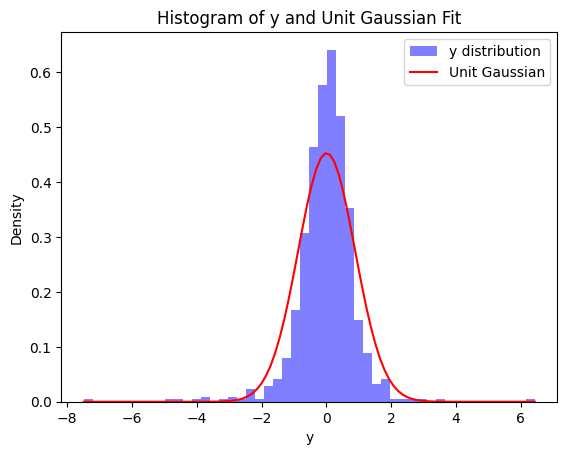

In [10]:
# Plot a histogram of y, and measure how close it is to a unit Gaussian
plt.hist(y, bins=50, density=True, alpha=0.5, color='blue', label='y distribution')
x = np.linspace(np.min(y), np.max(y), 100)
plt.plot(x, scipy.stats.norm.pdf(x, np.mean(y), np.std(y)), color='red', label='Unit Gaussian')
plt.title('Histogram of y and Unit Gaussian Fit')
plt.xlabel('y')
plt.ylabel('Density')
plt.legend()
plt.show()

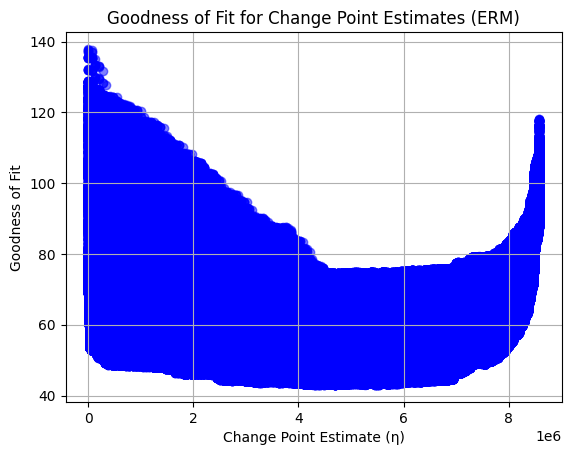

WERM chpt estimate:  [ 90 162 272]
Change point dates (ERM):  ['1975-01' '1987-01' '2005-05']
Done optimizing gof erm.


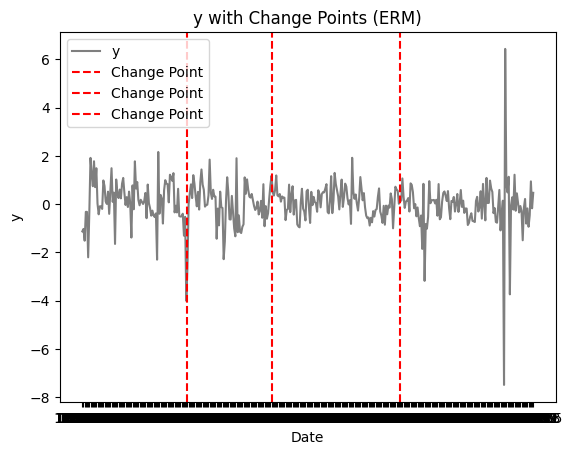

In [5]:
# Scatter the gof list
plt.scatter(np.arange(len(gof_list)), gof_list, c='blue', alpha=0.5)
plt.title('Goodness of Fit for Change Point Estimates (ERM)')
plt.xlabel('Change Point Estimate (η)')
plt.ylabel('Goodness of Fit')
plt.grid()
plt.show()
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", η̂)
# Print the dates associated with the change points
chgpt_dates_erm = date[η̂]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

# Inspect Regression Vectors

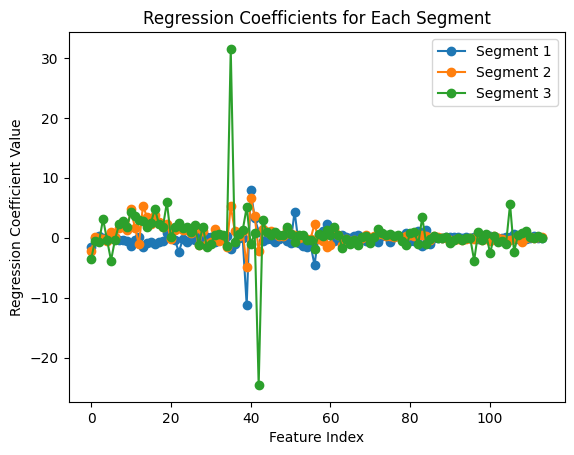

In [16]:
# Segment the data based on the estimated change points, and compute the regression vector for each segment
segments = []
# Ensure η̂ includes the start and end of the data points
# Example: η̂ = [0, 50, 100, 150] for data with 150 points and 3 segments
η̂_extended = np.concatenate(([0], η̂, [len(y)]))  # Add start and end indices
for i in range(0, len(η̂_extended)-1):
    start = η̂_extended[i]
    end = η̂_extended[i + 1]
    segment_X = X[start:end, :]
    segment_y = y[start:end]
    segments.append((segment_X, segment_y))

# Compute the regression vector for each segment
# p should be the number of features, i.e., X.shape[1]
# L should be the number of segments, i.e., len(segments)
p = X.shape[1]
B̂_segments = np.zeros((p, len(segments)))

# Use enumerate to get both the index (i) and the data (segment)
for i, (segment_X, segment_y) in enumerate(segments):
    sample_weight = np.ones(segment_X.shape[0]) / segment_X.shape[0]  # Uniform weights
    empirical_risk = lambda β: jnp.multiply(M(segment_X @ β, segment_y), sample_weight).sum()
    
    # Ensure the initial guess has the correct shape (p,)
    initial_guess = np.zeros(p)
    
    res = scipy.optimize.minimize(empirical_risk, initial_guess, jac=jax.grad(empirical_risk), method='L-BFGS-B')
    
    # Use the index 'i' from enumerate for correct assignment
    B̂_segments[:, i] = res.x

# Plot the regression vector values for each segment
num_segments = B̂_segments.shape[1]
for ℓ in range(num_segments):
    # Corrected the label to use the segment index ℓ
    plt.plot(np.arange(p), B̂_segments[:, ℓ], label=f'Segment {ℓ+1}', marker='o')

plt.xlabel('Feature Index')
plt.ylabel('Regression Coefficient Value')
plt.title('Regression Coefficients for Each Segment')
plt.legend()
plt.show()

In [7]:
y.shape

(387,)

In [8]:
X.shape

(387, 114)

In [10]:
segment_X.shape

(110, 114)

In [13]:
segment_y.shape

(110,)

In [12]:
segments.index((segment_X, segment_y))

ValueError: operands could not be broadcast together with shapes (72,114) (110,114) 

In [15]:
(segment_X, segment_y)

(array([[ 0.07613151,  0.31765296, -0.39830689, ..., -1.38215049,
         -0.13204158, -0.55852267],
        [-0.12682225, -0.1705261 , -0.12639859, ...,  1.58335979,
         -0.00505133,  0.18542606],
        [-0.30342986, -0.202061  , -0.04362784, ...,  0.57732183,
          0.40331853,  0.03957114],
        ...,
        [-0.05288516, -0.20862615, -0.08682139, ..., -0.33340029,
          0.89830965, -0.04451295],
        [-0.08741294, -0.0126345 , -0.1703772 , ..., -0.01724417,
          0.12660457,  2.15547875],
        [-0.06644793, -0.07637444, -0.17031469, ..., -0.24136788,
         -0.53907449, -0.73789514]], shape=(110, 114)),
 array([ 1.17651692,  0.47776234,  0.35501374,  0.57622038,  1.18855661,
         0.36893136,  0.32175588,  0.41943903,  0.10210696,  0.3193322 ,
         0.25798976,  0.27143652, -0.6620578 , -0.23613416, -0.20180511,
         0.80809872, -0.33139021,  0.39050117,  0.74041784, -0.43337958,
         0.15328938,  0.17632335, -0.84037456, -0.92440183, -0.